In [29]:
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
import os
import glob
import pandas as pd

## Dataset

In [19]:
img = Image.open('../bloodcells_dataset/eosinophil/EO_27.jpg')
width, height = img.size

print(f'width of image: {width} pixels')
print(f'height of image: {height} pixels')

width of image: 360 pixels
height of image: 363 pixels


In [26]:
t = transforms.ToTensor()
tensor_img = t(img)

tensor_img

tensor([[[0.8510, 0.8471, 0.8471,  ..., 0.9608, 0.9725, 0.9804],
         [0.8471, 0.8471, 0.8471,  ..., 0.9765, 0.9843, 0.9922],
         [0.8471, 0.8471, 0.8471,  ..., 0.9922, 1.0000, 1.0000],
         ...,
         [0.8471, 0.8549, 0.8510,  ..., 0.8706, 0.9020, 0.9216],
         [0.8471, 0.8549, 0.8510,  ..., 0.8902, 0.9176, 0.9333],
         [0.8471, 0.8549, 0.8510,  ..., 0.9020, 0.9216, 0.9373]],

        [[0.7137, 0.7098, 0.7098,  ..., 0.8549, 0.8667, 0.8745],
         [0.7098, 0.7098, 0.7098,  ..., 0.8706, 0.8784, 0.8863],
         [0.7098, 0.7098, 0.7098,  ..., 0.8863, 0.8941, 0.8980],
         ...,
         [0.7294, 0.7255, 0.7216,  ..., 0.7490, 0.7804, 0.8078],
         [0.7294, 0.7255, 0.7216,  ..., 0.7686, 0.8000, 0.8196],
         [0.7294, 0.7255, 0.7216,  ..., 0.7843, 0.8039, 0.8275]],

        [[0.6902, 0.6863, 0.6863,  ..., 0.7490, 0.7529, 0.7569],
         [0.6863, 0.6863, 0.6863,  ..., 0.7647, 0.7647, 0.7725],
         [0.6863, 0.6863, 0.6863,  ..., 0.7804, 0.7804, 0.

In [28]:
tensor_img.shape

torch.Size([3, 363, 360])

In [9]:
sample_addreses = [
    {'class': 'basophil', 'address': '../bloodcells_dataset/basophil/BA_47.jpg'},
    {'class': 'eosinophil', 'address': '../bloodcells_dataset/eosinophil/EO_27.jpg'},
    {'class': 'erythroblast', 'address': '../bloodcells_dataset/erythroblast/ERB_233.jpg'},
    {'class': 'ig', 'address': '../bloodcells_dataset/ig/IG_5887.jpg'},
    {'class': 'lymphocyte', 'address': '../bloodcells_dataset/lymphocyte/LY_3530.jpg'},
    {'class': 'monocyte', 'address': '../bloodcells_dataset/monocyte/MO_1524.jpg'},
    {'class': 'neutrophil', 'address': '../bloodcells_dataset/neutrophil/BNE_715.jpg'},
    {'class': 'platelet', 'address': '../bloodcells_dataset/platelet/PLATELET_344.jpg'}
]

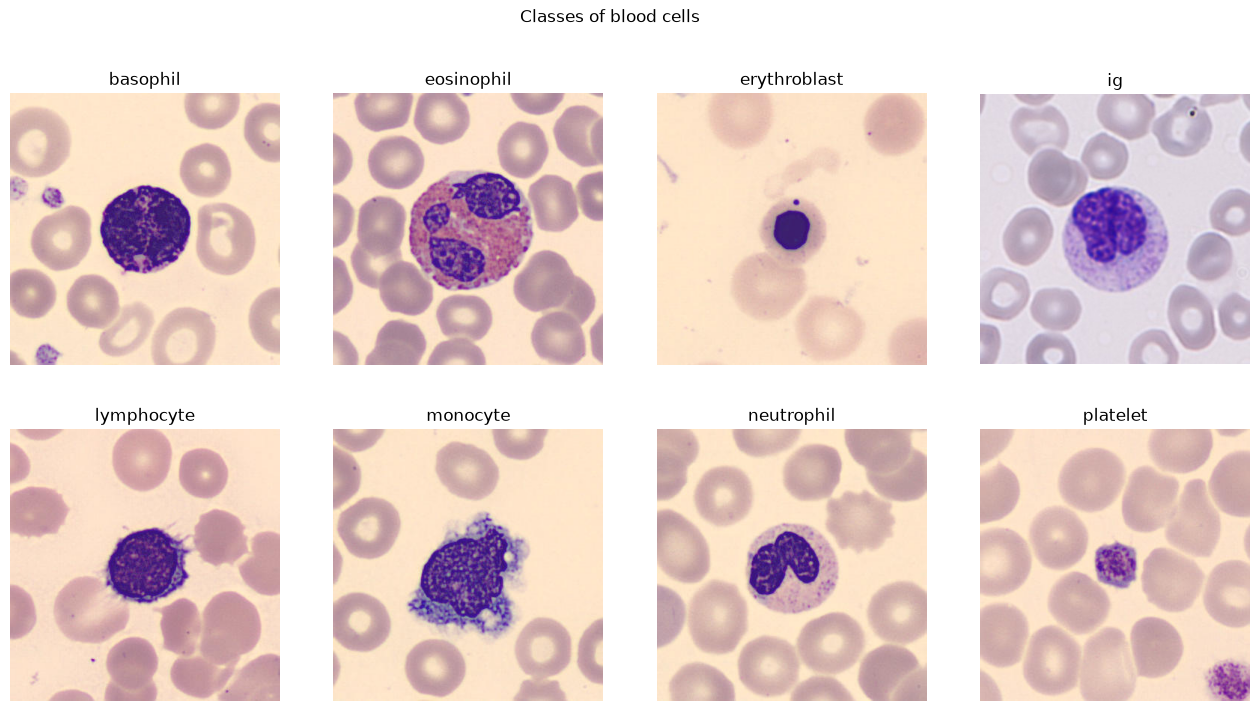

In [12]:
fig, axes = plt.subplots(ncols=4, nrows=2, figsize=(16, 8))
axes_flatten = axes.flatten()
fig.suptitle('Classes of blood cells')

for i, sample in enumerate(sample_addreses):
    axes_flatten[i].imshow(Image.open(sample['address']))
    axes_flatten[i].set_title(sample['class'])
    axes_flatten[i].set_axis_off()

In [20]:
dataset = datasets.ImageFolder(root='../bloodcells_dataset')
print(f"Number of images in dataset: {len(dataset)}")
print(f"Number of classes: {dataset.classes}")
print(f"Mapping classes to numbers: {dataset.class_to_idx}")

Number of images in dataset: 17092
Number of classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Mapping classes to numbers: {'basophil': 0, 'eosinophil': 1, 'erythroblast': 2, 'ig': 3, 'lymphocyte': 4, 'monocyte': 5, 'neutrophil': 6, 'platelet': 7}


In [35]:
dataset_dir = '../bloodcells_dataset' 
base_dir = os.getcwd() 
data = []

class_names = sorted(os.listdir(dataset_dir))

for class_name in class_names:
    class_path = os.path.join(dataset_dir, class_name)
    
    if os.path.isdir(class_path):

        extensions = ('*.jpg', '*.jpeg', '*.png', '*.bmp')
        image_paths = []
        

        for ext in extensions:
            image_paths.extend(glob.glob(os.path.join(class_path, ext)))
            image_paths.extend(glob.glob(os.path.join(class_path, ext.upper())))
        
        image_paths = list(set(image_paths))
        
        for img_path in image_paths:

            relative_img_path = os.path.relpath(img_path, start=base_dir)

            relative_img_path = relative_img_path.replace('\\', '/')
            
            data.append({
                'image_path': relative_img_path,
                'class_name': class_name
            })

df = pd.DataFrame(data)

df['class_id'] = df['class_name'].astype('category').cat.codes

csv_output_path = 'dataset_info.csv'
df.to_csv(csv_output_path, index=False, encoding='utf-8')

In [36]:
df

,image_path,class_name,class_id
0,../bloodcells_dataset/basophil/BA_317405.jpg,basophil,0
1,../bloodcells_dataset/basophil/BA_835645.jpg,basophil,0
2,../bloodcells_dataset/basophil/BA_566824.jpg,basophil,0
3,../bloodcells_dataset/basophil/BA_383453.jpg,basophil,0
4,../bloodcells_dataset/basophil/BA_767164.jpg,basophil,0
...,...,...,...
17087,../bloodcells_dataset/platelet/PLATELET_890075...,platelet,7
17088,../bloodcells_dataset/platelet/PLATELET_610485...,platelet,7
17089,../bloodcells_dataset/platelet/PLATELET_140323...,platelet,7
17090,../bloodcells_dataset/platelet/PLATELET_753131...,platelet,7
